In [35]:
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.size": 12,
})

textwidth_pt = 472
inch_per_pt = 1 / 72.27
fig_width = textwidth_pt * inch_per_pt
fig_height = fig_width * 0.65

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import copy
import itertools
import pypesto
import petab
import fides
import pypesto.petab
import pypesto.optimize as optimize
import pypesto.visualize as visualize
import pypesto.visualize.model_fit
import amici
import numpy as np
import numpy.matlib as nm
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import libsbml
import sys
from pypesto.store import save_to_hdf5
import dill
import pypesto.hierarchical
from pypesto.store import read_from_hdf5
import os
from pathlib import Path

PROJECT_ROOT = next(
    path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "petab").is_dir() and (path / "results").is_dir() and (path / "src").is_dir()
)
os.chdir(PROJECT_ROOT)
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))
PETAB_DIR = PROJECT_ROOT / "petab"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
MODEL_SELECTION_RESULTS_DIR = RESULTS_DIR / "model_selection" / "all_ligands_sacess_brute_force_mixed_noise"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
(MODEL_SELECTION_RESULTS_DIR / "figures").mkdir(parents=True, exist_ok=True)
(MODEL_SELECTION_RESULTS_DIR / "figures" / "clustering").mkdir(parents=True, exist_ok=True)

import src.functionalities as func
import src.model_selection_functionalities as msfunc

In [37]:
import importlib
importlib.reload(func)
importlib.reload(msfunc)

from matplotlib.pyplot import cm

In [38]:
import petab_select
from petab_select.constants import PETAB_PROBLEM
from pypesto.select import model_to_pypesto_problem

In [ ]:
param_to_reaction = {
    'tau_eL': r'$\mathrm{R_{1}}$',
    'k1_Lentry': r'$\mathrm{R_{2}}$',
    'k2_Lentry': r'$\mathrm{R_{3}}$',
    'const_l_degrad': r'$\mathrm{R_{4}}$',
    'v_AhR': r'$\mathrm{R_{5}}$',
    'tau_AhR': r'$\mathrm{R_{6}}$',
    'k1_AhRL': r'$\mathrm{R_{7}}$',
    'k_diss_AhRL': r'$\mathrm{R_{-7}}$',
    'k1_nuclearimport': r'$\mathrm{R_{8}}$',
    'tau_nAhRL': r'$\mathrm{R_{9}}$',
    'v_nARNT': r'$\mathrm{R_{10}}$',
    'tau_nARNT': r'$\mathrm{R_{11}}$',
    'k1_heterodim': r'$\mathrm{R_{12}}$',
    'k_diss_heterodim': r'$\mathrm{R_{-12}}$',
    'k1_dna_ahrr': r'$\mathrm{R_{13}}$',
    'k_diss_dna_ahrr': r'$\mathrm{R_{-13}}$',
    'k1_dna_cyp': r'$\mathrm{R_{14}$',
    'k_diss_dna_cyp': r'$\mathrm{R_{-14}}$',
    'b_AhRR': r'$\mathrm{R_{15}}$',
    'b_AhRR_basal': r'$\mathrm{R_{16}}$',
    'tau_mRNA_AhRR': r'$\mathrm{R_{17}}$',
    'rho_Cyp': r'$\mathrm{R_{18}}$',
    'b_Cyp_basal': r'$\mathrm{R_{19}}$',
    'tau_mRNA_Cyp': r'$\mathrm{R_{20}}$',
    'm_Cyp': r'$\mathrm{R_{21}}$',
    'tau_Cyp1a1': r'$\mathrm{R_{22}}$',
    'k1_Cyp1a1': r'$\mathrm{R_{23}}$',
    'm_AhRR': r'$\mathrm{R_{24}}$',
    'tau_AhRR': r'$\mathrm{R_{25}}$',
    'k1_AhRR_ARNT': r'$\mathrm{R_{26}}$',
    'k_diss_AhRR_ARNT': r'$\mathrm{R_{-26}}$',
    'k1_rep_dna_ahrr': r'$\mathrm{R_{27}}$',
    'k_diss_rep_dna_ahrr': r'$\mathrm{R_{-27}}$',
    'k1_rep_dna_cyp': r'$\mathrm{R_{28}}$',
    'k_diss_rep_dna_cyp': r'$\mathrm{R_{-28}}$',
}

In [40]:
def objective_customizer(objective):
    objective.amici_solver.setMaxSteps(100000)
    objective.amici_solver.setRelativeTolerance(1e-12)
    objective.amici_solver.setAbsoluteTolerance(1e-8)
    objective.amici_solver.setSensitivityMethod(amici.SensitivityMethod_adjoint)
    return None

In [41]:
os.getcwd()
output_path = Path(os.path.join(os.getcwd(), "results/model_selection/all_ligands_sacess_brute_force_mixed_noise/"))

petab_select_yaml = Path(os.getcwd()) / 'petab' / 'model_selection' / 'petab_select_all_ligands_brute_force_mixed_noise' / 'petab_select_problem_brute_force.yaml'
petab_select_problem = petab_select.Problem.from_yaml(petab_select_yaml)

In [42]:
petab_yaml = Path(os.getcwd()) / 'petab' / 'model_selection' / 'petab_select_all_ligands_brute_force_mixed_noise' / 'full_petab_problem.yaml'

selection_petab_problem = petab.Problem.from_yaml(petab_yaml)

selection_pypesto_importer = pypesto.petab.PetabImporter(selection_petab_problem, hierarchical=False)
selection_model = selection_pypesto_importer.create_model(force_compile=False)

# Mixed Noise Model
After the Famos search revealed no improvement for models with more than two free parameters, we did a Brute Force strategy, where we calibrate all models, that differ just in one or two parameters.

### Set models as inputs

In [43]:
import itertools

def generate_vectors(length):
    # Generate vectors with exactly one 1
    one_ones = [list(x) for x in itertools.combinations(range(length), 1)]
    
    # Generate vectors with exactly two 1s
    two_ones = [list(x) for x in itertools.combinations(range(length), 2)]
    
    vectors = []
    
    # Create binary vectors for one 1
    for positions in one_ones:
        vector = [0] * length
        for pos in positions:
            vector[pos] = 1
        vectors.append(vector)
    
    # Create binary vectors for two 1s
    for positions in two_ones:
        vector = [0] * length
        for pos in positions:
            vector[pos] = 1
        vectors.append(vector)
    
    return vectors

In [44]:
# Get all vectors of length 16 with exactly 1 or 2 ones
indices_array = generate_vectors(16)

## Selection result from sacess brute force selection


In [45]:
report = pd.read_csv(f'{output_path}/report/brute_force_report_short.tsv', sep='\t').set_index("model_id")

model_ids_total = report.index

print('Number of calibrated models: ', end='')
print(len(model_ids_total))

best_models = {
    criterion: {'model_id': [], 'value': []}
    for criterion in ["NLLH", 'AIC', 'AICc', 'BIC']
}

for criterion in best_models:
    model_id = report[criterion].idxmin()
    value = report.loc[model_id, criterion]
    best_models[criterion]['model_id'].append(model_id)

    best_models[criterion]['value'].append(value)


best_model_dfs = {
    criterion: pd.DataFrame(data=best_models[criterion])
    for criterion in best_models
}

Number of calibrated models: 544


In [46]:
calibrated_list = []
for yaml_file in os.listdir(os.path.join(output_path, "history")):
    model = petab_select.model.Model.from_yaml(os.path.join(output_path, f"history/{yaml_file}"))
    calibrated_list.append(model)

In [47]:
from petab_select.constants import Criterion

calibrated_models = petab_select.models.Models(calibrated_list)

corrected_akaike_weights = petab_select.analyze.compute_weights(calibrated_models, Criterion.AICC)
akaike_weights = petab_select.analyze.compute_weights(calibrated_models, Criterion.AIC)
bic_weights = petab_select.analyze.compute_weights(calibrated_models, Criterion.BIC)

In [48]:
best_AICc = best_model_dfs["AICc"]["value"].values[0]
best_BIC = best_model_dfs["BIC"]["value"].values[0]
best_AIC = best_model_dfs["AIC"]["value"].values[0]
AICc_threshold = 10

evaluated_models = pd.DataFrame(columns=["model_id", "AICc","delta AICc",  "AIC", "BIC", "Akaike weight", "n_par estimated", "estimated parameter"])


for index, model in enumerate(calibrated_models):
    model_id = model.model_id
    AICc = report.loc[model_id, "AICc"]
    AIC = report.loc[model_id, "AIC"]
    BIC = report.loc[model_id, "BIC"]

    subspace_id = model_id.split('-')[0]
    model_indices = [int(i) for i in model_id.split('-')[1]]
    est_par = [k for k,v in petab_select_problem.model_space.model_subspaces[subspace_id].indices_to_parameters(model_indices).items() if v == 'estimate']
    evaluated_models = pd.concat([evaluated_models, pd.DataFrame({"model_id": [subspace_id], 
                                                "NLLH": [report.loc[model_id, "NLLH"]],
                                                "AICc": [AICc],
                                                "AIC": [AIC],
                                                "BIC": [BIC],
                                                "delta AICc":  np.abs([best_AICc - AICc]),
                                                "delta AIC": np.abs([best_AIC - AIC]),
                                                "delta BIC": np.abs([best_BIC - BIC]),
                                                "Akaike weight": akaike_weights[index], 
                                                "BIC weight": bic_weights[index],
                                                "corr. Akaike weight": corrected_akaike_weights[index],
                                                "n_par estimated": [len(est_par)], 
                                                "estimated parameter": [est_par] 
                                                    })],
                                                ignore_index=True)
    evaluated_models.reset_index()

# store as csv
evaluated_models.drop_duplicates(subset=["estimated parameter"], inplace=True)    
evaluated_models.sort_values(by=["delta AIC"], ascending=True, inplace=True)
# evaluated_models.to_csv(f'{output_path}/sacess_eval_df.tsv', sep='\t')


Add the numbers to the parameters for later plotting.

In [ ]:
param_to_number = {
    'c_eL': r'$\mathrm{R_{1}}$',
    'c1_Lentry': r'$\mathrm{R_{2}}$',
    'c2_Lentry': r'$\mathrm{R_{3}}$',
    'c1_AhRL': r'$\mathrm{R_{7}}$',
    'c2_AhRL': r'$\mathrm{R_{-7}}$',
    'c1_nuclearimport': r'$\mathrm{R_{8}}$',
    'c_nAhRL': r'$\mathrm{R_{9}}$',
    'c1_heterodim': r'$\mathrm{R_{12}}$',
    'c2_heterodim': r'$\mathrm{R_{-12}}$',
    'c1_dna_ahrr': r'$\mathrm{R_{13}}$',
    'c2_dna_ahrr': r'$\mathrm{R_{-13}}$',
    'c1_dna_cyp': r'$\mathrm{R_{14}}$',
    'c2_dna_cyp': r'$\mathrm{R_{-14}}$',
    'c_AhRR': r'$\mathrm{R_{15}}$',
    'c1_Cyp1a1': r'$\mathrm{R_{23}}$',
    'c_Cyp': r'$\mathrm{R_{28}}$',
}

# iterate over rows and append numbers to parameter names
for _, row in evaluated_models.iterrows(): 
    numbered_pars = [f"{param_to_number[par.split('_', 1)[1]]} ({par.split('_', 1)[0]}/3MC)" for par in row["estimated parameter"]]
    new_par_names = [s.replace("MC3/3MC", "3MC/ICZ" ) for s in numbered_pars]
    evaluated_models.at[row.name, "estimated parameter"] = new_par_names

In [50]:
threshold = 10
bic_models = evaluated_models[evaluated_models["delta BIC"] < threshold]
aic_models = evaluated_models[evaluated_models["delta AIC"] < threshold]
aicc_models = evaluated_models[evaluated_models["delta AICc"] < threshold]

Note only 12 out of the 16 possible parameters were considered.

In [51]:
aic_pypesto_problems = {}
for model_id in aic_models.model_id:
    selection_pypesto_model = pypesto.select.model_to_pypesto_problem(petab_select_problem.get_model(model_id, [0]))
    objective_customizer(selection_pypesto_model.objective)
    aic_pypesto_problems[model_id] = selection_pypesto_model
# with open(f"results/model_selection/all_ligands_sacess_brute_force_mixed_noise/aic_pypesto_problems_dict.dill", "wb") as f:
#     dill.dump(aic_pypesto_problems, f)

### Reestimation of AIC models
We did then ran optimization for those models again. For all models the optimum found during the selection was better or indistinguishable in terms of the NLLH. So for the AIC reporting and results we are safe to use the model selection result.

In [52]:
with open(f"results/model_selection/all_ligands_sacess_brute_force_mixed_noise/best/best_aics_dict.dill", "rb") as f:
    best_aics = dill.load(f)
with open(f"results/model_selection/all_ligands_sacess_brute_force_mixed_noise/best/best_nllhs_dict.dill", "rb") as f:
    best_nllhs = dill.load(f)

In [53]:
comparison_df = pd.DataFrame(columns=["model_id", "selection NLLH", "new NLLH", "selection AIC", "new AIC", "n_par estimated"])
for model_id, best_nllh in best_nllhs.items():
    comparison_df = pd.concat([comparison_df, pd.DataFrame({
        "model_id": model_id,
        "selection NLLH": evaluated_models.loc[evaluated_models["model_id"] == model_id, "NLLH"],
        "new NLLH": best_nllh,
        "selection AIC": evaluated_models.loc[evaluated_models["model_id"] == model_id, "AIC"],
        "new AIC": best_aics[model_id],
        "n_par estimated": evaluated_models.loc[evaluated_models["model_id"] == model_id, "n_par estimated"]
    })],
    ignore_index=True)

In [54]:
comparison_df

,model_id,selection NLLH,new NLLH,selection AIC,new AIC,n_par estimated
0,M100,214.665659,222.269575,517.331318,532.539151,4
1,M11,214.631816,214.620751,517.263632,517.241502,4
2,M114,215.286926,213.947076,518.573851,515.894152,4
3,M117,215.328062,218.166031,518.656123,524.332062,4
4,M360,212.699196,219.676005,509.398393,523.352010,2
5,M64,214.810925,217.357607,517.621850,522.715215,4
6,M78,213.816226,213.816224,515.632451,515.632448,4
7,M8,214.517395,219.432611,517.034790,526.865222,4
8,M83,212.840068,218.673259,513.680135,525.346518,4
9,M87,212.138145,211.323721,512.276290,510.647442,4


## Visualizations

## Best model fit

In [55]:
best_model = "M360"
best_model_result =  pypesto.store.read_result(f"results/model_selection/all_ligands_sacess_brute_force_mixed_noise/best/full_result_{best_model}.hdf5")
best_model_pypesto_problem = aic_pypesto_problems[best_model]

Loading the sampling result failed. It is highly likely that no sampling result exists within output/model_selection/all_ligands_sacess_brute_force_mixed_noise/best/full_result_M360.hdf5.


The objective function value is 212.69919644823148



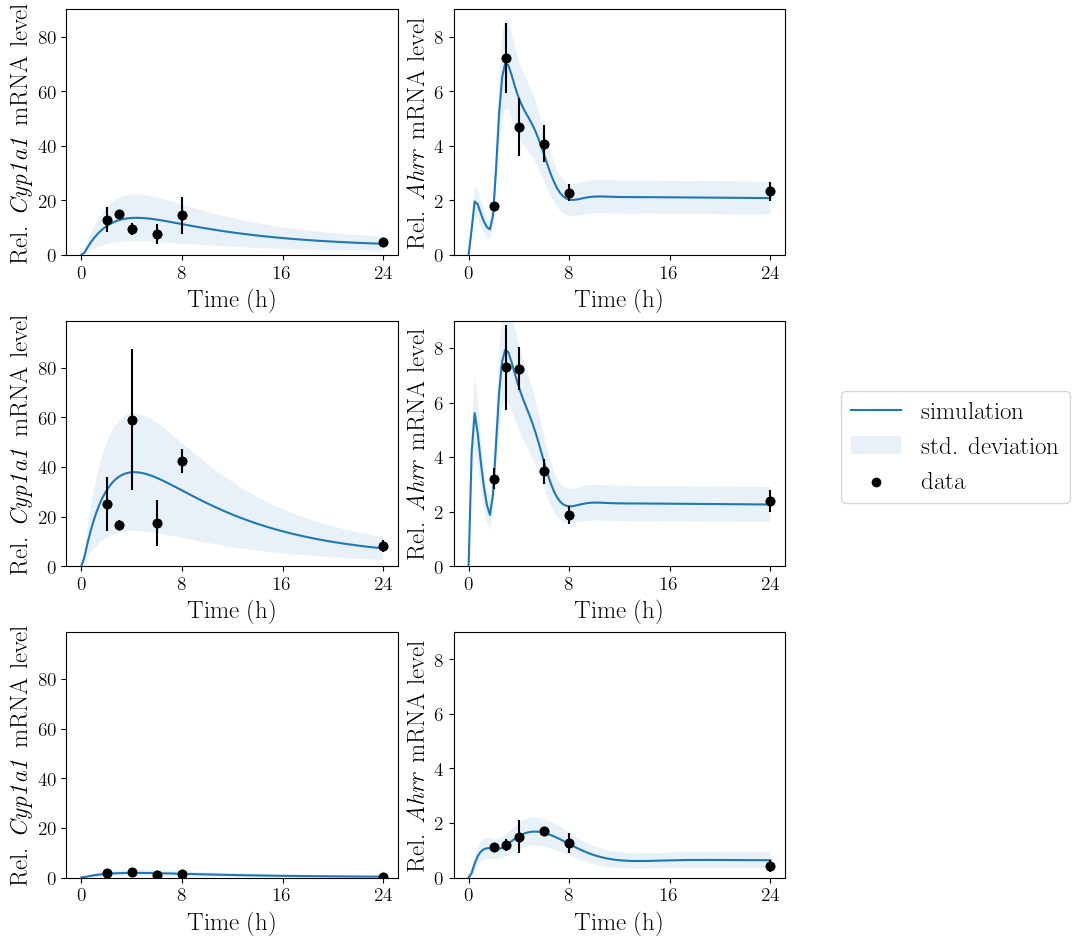

In [56]:
best_model_fig, best_model_axs = func.custom_visualize_model_fit(best_model_result, 
                                                                 best_model_pypesto_problem, 
                                                                 selection_petab_problem, 
                                                                 figsize = (1.2*fig_width, 2.2*fig_height),
                                                                 start_index=0)
observable_labels = [r"Rel. \textit{Cyp1a1} mRNA level", r"Rel. \textit{Ahrr} mRNA level"]
for axs in best_model_axs:
    for index, ax in enumerate(axs):
        ax.set_title("")
        ax.set_ylabel(observable_labels[index], fontsize=18)
        ax.get_legend().remove()
        ax. set_xlabel("Time (h)", fontsize=18)
        for item in (ax.get_xticklabels() + ax.get_yticklabels()):
            item.set_fontsize(14)
best_model_axs.flat[0].set_ylim(0,90)
best_model_axs.flat[1].set_ylim(0,9)
handles, labels = best_model_fig.axes[0].get_legend_handles_labels()
best_model_fig.legend(handles, labels, bbox_to_anchor=(1.05, 0.6), loc='upper left', fontsize=18)

best_model_fig.savefig(f"results/model_selection/all_ligands_sacess_brute_force_mixed_noise/figures/best_model_{best_model}_model_fit.png", dpi=600, bbox_inches="tight")

## UpsetPlot


In [58]:
plot_aic_models = copy.deepcopy(aic_models)
for i, row in plot_aic_models.iterrows():
    plot_aic_models.at[i, "estimated parameter"] = [('{: >20}'.format(par)) for par in row["estimated parameter"]]

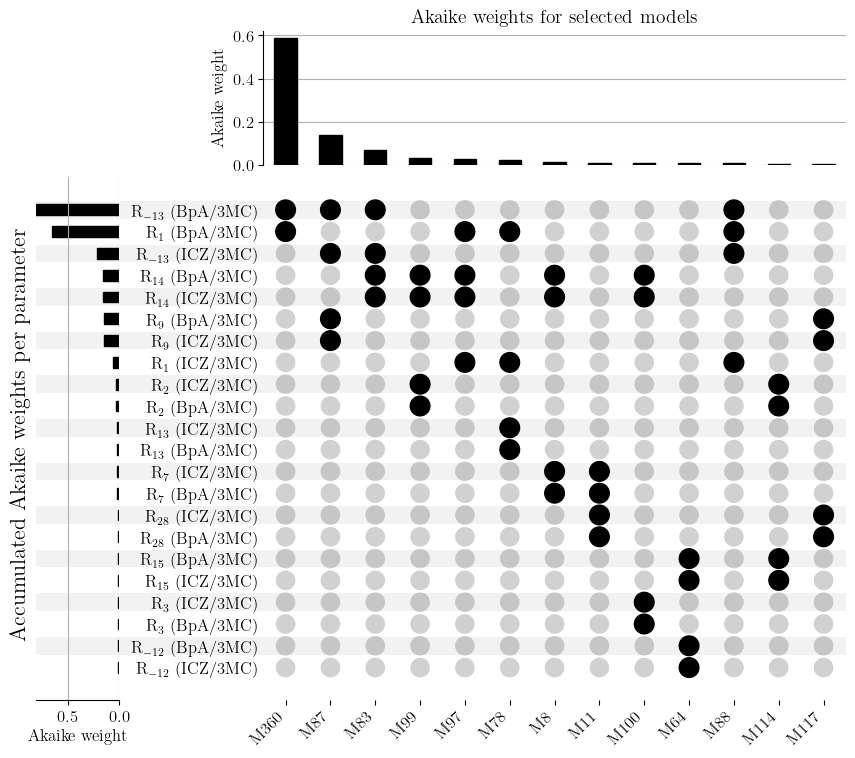

In [59]:
from upsetplot import from_memberships, UpSet
plt.rcParams.update({"font.size": 12})
model_by_par = from_memberships(plot_aic_models["estimated parameter"], data=aic_models)
fig = plt.figure(figsize=(1.6*fig_width, 2.5*fig_height))
upset = UpSet(model_by_par[0:20], sum_over="Akaike weight", with_lines=False, sort_by="cardinality", element_size=None
              )
d = upset.plot(fig=fig)
plt.title("Akaike weights for selected models", fontsize=14)
d["totals"].set_ylabel("Per parameter", fontsize=14)
d["intersections"].set_ylabel("Akaike weight", fontsize=12)
d["totals"].set_xlabel("Akaike weight", fontsize=12)
d["totals"].invert_yaxis()


xlabels = model_by_par["model_id"].values
ax = d["matrix"]
# Create a second axis aligned with the matrix
ax_bottom = ax.twiny()
ax_bottom.set_xlim(ax.get_xlim())

# Place labels at the bottom
ax_bottom.set_xticks(range(len(xlabels)))
ax_bottom.set_xticklabels(xlabels, rotation=45, ha="right", fontsize=12, fontweight="bold")

# Hide the spines so only labels show
for spine in ["top", "bottom", "left", "right"]:
    ax_bottom.spines[spine].set_visible(False)

# Force labels to bottom
ax_bottom.xaxis.set_ticks_position("bottom")
ax_bottom.xaxis.set_label_position("bottom")
fig.text(0.1, 0.5, "Accumulated Akaike weights per parameter", va="center", rotation="vertical", fontsize=16)
# Add space underneath
plt.subplots_adjust(bottom=0.25)
plt.tight_layout()

plt.show()

fig.savefig(f"results/model_selection/all_ligands_sacess_brute_force_mixed_noise/figures/upset_by_akaike_weights_new.png", dpi=600, bbox_inches="tight")

## Clustering

And for clustering we integrated all trajectories of both runs into one result file (full_result) and do the clustering on all available trajectories.

--> Check thoroughly that all these trajectories are used and not only the ones from the reestimation. This would otherwise not match the model selection results and we are screwed...

In [60]:
from tslearn.metrics import dtw, cdist_dtw
from tslearn.clustering import TimeSeriesKMeans

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from tslearn.metrics import cdist_soft_dtw
from sklearn.metrics import euclidean_distances

In [61]:
def overall_distance_matrix_euclid(time_series, log=False):
    """
    Compute the overall distance matrix averaged over all conditions using eucliedean distance pointwise.
    ----------------------------------------------------------------
    Parameters
    ----------
    time_series : np.ndarray
        A 3D array of shape (n_samples, n_timepoints, n_conditions) containing the time series data.
    ----------------------------------------------------------------
    Returns
    -------
    dist_matrix : np.ndarray
        A 2D array representing the average distance matrix across all conditions.
    ----------------------------------------------------------------
    This function computes the average distance matrix across all conditions in the provided time series data.
    """
    dist_matrices = []
    for i in range(time_series.shape[-1]):
        dist_matrices.append(euclidean_distances(time_series[:, :, i]))
    dist_matrix = np.mean(dist_matrices, axis=0)
    return dist_matrix

def overall_distance_matrix_dtw(time_series, log=False):
    """
    Compute the overall distance matrix averaged over all conditions using Dynamic Time Warping (DTW).
    ----------------------------------------------------------------
    Parameters
    ----------
    time_series : np.ndarray
        A 3D array of shape (n_samples, n_timepoints, n_conditions) containing the time series data.
    ----------------------------------------------------------------
    Returns
    -------
    dist_matrix : np.ndarray
        A 2D array representing the average distance matrix across all conditions.
    ----------------------------------------------------------------
    This function computes the average distance matrix across all conditions in the provided time series data.
    """
    dist_matrices = []
    for i in range(time_series.shape[-1]):
        dist_matrices.append(cdist_dtw(time_series[:, :, i]))
    dist_matrix = np.mean(dist_matrices, axis=0)
    return dist_matrix

In [62]:
model = "bmm_model_reduced"
data = "BpA_3MC_ICZ_mixed_noise"
model_name = f"{model}_{data}"
yaml_file = f"petab/{data}/full_petab_problem.yaml"

petab_problem = petab.Problem.from_yaml(yaml_file)

In [63]:
with open(f"results/model_selection/all_ligands_sacess_brute_force_mixed_noise/aic_pypesto_problems_dict.dill", "rb") as f:
    aic_pypesto_problems_dict = dill.load(f)

best_models_eval_df = pd.read_csv(f'results/model_selection/all_ligands_sacess_brute_force_mixed_noise/best_models_eval_df.csv')

## Cluster based on all ensemble members time-series of ensembles
Taking all trajectories of all AIC models, that are within a cut-off of 10 from the best AIC value.

In [64]:
with open("results/model_selection/all_ligands_sacess_brute_force_mixed_noise/aic_trajectories_5_clusters.dill", "rb") as f:
   aic_5_clust = dill.load(f)
with open("results/model_selection/all_ligands_sacess_brute_force_mixed_noise/aic_trajectories_10_clusters.dill", "rb") as f:
   aic_10_clust = dill.load(f)
with open("results/model_selection/all_ligands_sacess_brute_force_mixed_noise/aic_trajectories_dist_matrix.dill", "rb") as f:
   aic_traj_dist_matrix = dill.load(f)
with open("results/model_selection/all_ligands_sacess_brute_force_mixed_noise/aic_trajectories_ensemble.dill", "rb") as f:
   aic_traj_ens = dill.load(f)

In [65]:
# if one wants to cluster again
aic_dist_matrix = aic_traj_dist_matrix
aic_8_clust = AgglomerativeClustering(n_clusters=8, metric='precomputed', linkage="complete", compute_distances=True, compute_full_tree=True)
aic_8_clust.fit(aic_dist_matrix)

AgglomerativeClustering(compute_distances=True, compute_full_tree=True,
                        linkage='complete', metric='precomputed', n_clusters=8)

In [66]:
importlib.reload(msfunc)

<module 'model_selection_functionalities' from '/home/vincent/PhD/Projects/Ahr_modelling/bmm_cell_model_reduced/model_selection_functionalities.py'>

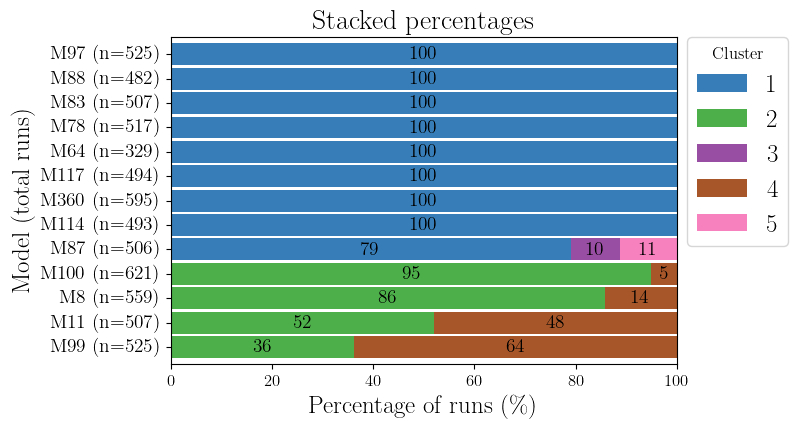

In [67]:
model_runs = aic_traj_ens.keys()
classes = aic_5_clust.labels_
clust_order = [4,3,2,1,0]
cmap = matplotlib.cm.get_cmap("Set1")
color_list = [cmap(i) for i in [1,2,3,6,7]]
fig, ax = msfunc.plot_model_class_stack(
    model_runs,
    classes,
    title="Stacked percentages",
    cluster_order=clust_order,
    annotate=True,
    annot_fontsize=14,
    text_fontsize=18,
    min_pct_label=5,
    colors=color_list,
    orientation="h",          # <- switch to "v" for vertical
    bar_height=0.9,
    min_fig_width=fig_width,
    fig_height=fig_height,
    fig_height_per_bar=0.3,
    tick_fontsize=14,
    class_labels = {0:1, 1:2, 2:3, 3:4, 4:5}
)
fig.savefig(f"results/model_selection/all_ligands_sacess_brute_force_mixed_noise/figures/clustering/aic_models_class_stack_5_clusters.png", dpi=600, bbox_inches="tight")

In [69]:
clust_0_ens = {k: val for k, val in aic_traj_ens.items() if aic_5_clust.labels_[list(aic_traj_ens.keys()).index(k)] == 0}
clust_1_ens = {k: val for k, val in aic_traj_ens.items() if aic_5_clust.labels_[list(aic_traj_ens.keys()).index(k)] == 1}
clust_2_ens = {k: val for k, val in aic_traj_ens.items() if aic_5_clust.labels_[list(aic_traj_ens.keys()).index(k)] == 2}
clust_3_ens = {k: val for k, val in aic_traj_ens.items() if aic_5_clust.labels_[list(aic_traj_ens.keys()).index(k)] == 3}
clust_4_ens = {k: val for k, val in aic_traj_ens.items() if aic_5_clust.labels_[list(aic_traj_ens.keys()).index(k)] == 4}

In [70]:
# clust_0_ens = {k: val for k, val in aic_traj_ens.items() if aic_10_clust.labels_[list(aic_traj_ens.keys()).index(k)] == 0}
# clust_1_ens = {k: val for k, val in aic_traj_ens.items() if aic_10_clust.labels_[list(aic_traj_ens.keys()).index(k)] == 1}
# clust_2_ens = {k: val for k, val in aic_traj_ens.items() if aic_10_clust.labels_[list(aic_traj_ens.keys()).index(k)] == 2}
# clust_3_ens = {k: val for k, val in aic_traj_ens.items() if aic_10_clust.labels_[list(aic_traj_ens.keys()).index(k)] == 3}
# clust_4_ens = {k: val for k, val in aic_traj_ens.items() if aic_10_clust.labels_[list(aic_traj_ens.keys()).index(k)] == 4}
# clust_5_ens = {k: val for k, val in aic_traj_ens.items() if aic_10_clust.labels_[list(aic_traj_ens.keys()).index(k)] == 5}
# clust_6_ens = {k: val for k, val in aic_traj_ens.items() if aic_10_clust.labels_[list(aic_traj_ens.keys()).index(k)] == 6}
# clust_7_ens = {k: val for k, val in aic_traj_ens.items() if aic_10_clust.labels_[list(aic_traj_ens.keys()).index(k)] == 7}
# clust_8_ens = {k: val for k, val in aic_traj_ens.items() if aic_10_clust.labels_[list(aic_traj_ens.keys()).index(k)] == 8}
# clust_9_ens = {k: val for k, val in aic_traj_ens.items() if aic_10_clust.labels_[list(aic_traj_ens.keys()).index(k)] == 9}

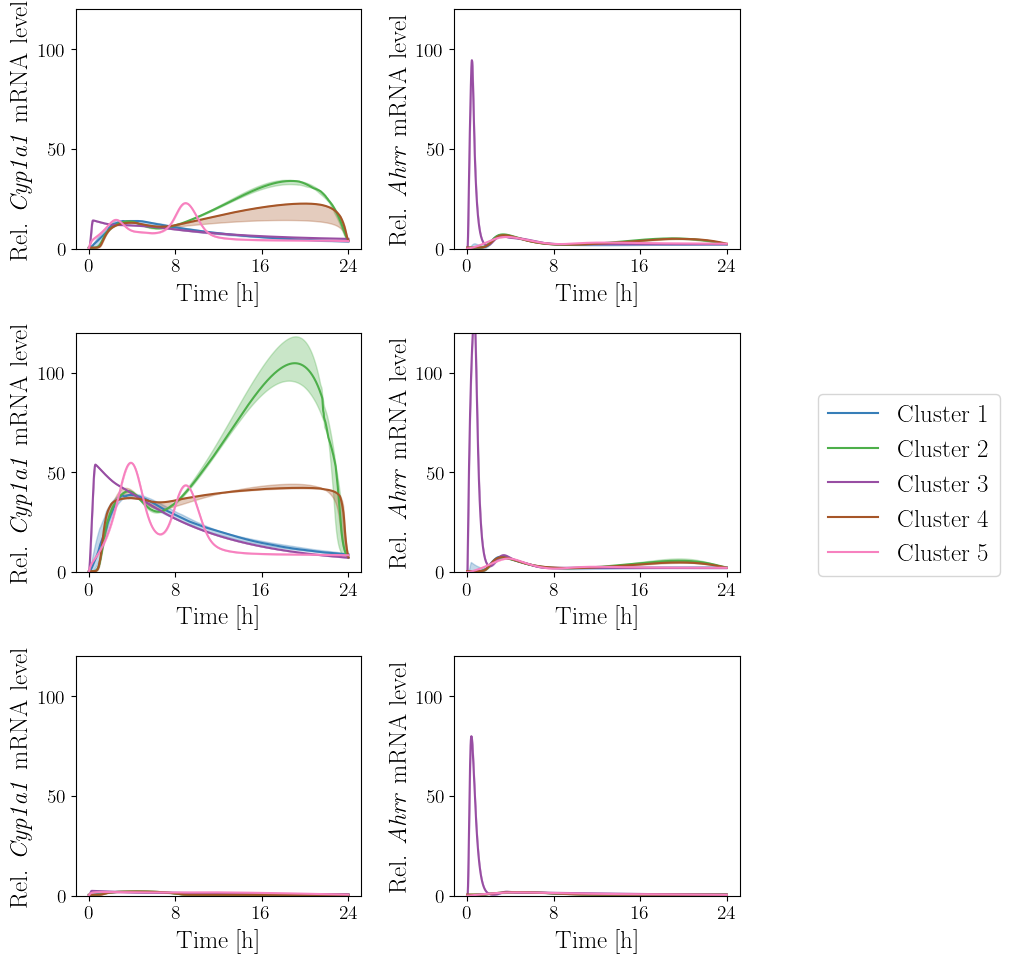

In [ ]:
plt.rcParams.update({'font.size': 18})

n_clust = 5
# cmap = matplotlib.cm.get_cmap("tab10")
# color_list = [cmap(i/np.maximum(1, n_clust-1)) for i in range(n_clust)]


conditions = ["obs_MC1000", "obs_ICZ", "obs_BpA" , ]
observable_labels = [r"Rel. \textit{Cyp1a1} mRNA level", r"Rel. \textit{Ahrr} mRNA level"]
observable_ids = petab_problem.get_observable_ids()
meas_df = petab_problem.measurement_df
meas_timepoints = sorted(meas_df['time'].unique())

sim_timepoints = aic_traj_ens["M100_0"]["t"]
ticks_times = []
for t in np.array(range(0,56,8)):
        if 3600*t <= sim_timepoints[-1]:
                ticks_times.append(t)

fig, ax = plt.subplots(3,2, figsize=(1.2*fig_width, 2.35*fig_height))

clusters = [0,1,3]

ylimits = [(0, 120), (0, 9)]

cluster_ensembles = [clust_0_ens, clust_1_ens, clust_2_ens, clust_3_ens, clust_4_ens]
# cluster_ensembles = [clust_0_ens, clust_1_ens, clust_2_ens, clust_3_ens, clust_4_ens, clust_5_ens, clust_6_ens, clust_7_ens, clust_8_ens, clust_9_ens]
for i_clust, clust_ensemble in zip(clusters, np.array(cluster_ensembles)[clusters]): 
    color = color_list[i_clust]
    for i_cond, condition in enumerate(conditions):
        observable_simulations = np.stack([ens_member[condition] for ens_member in clust_ensemble.values()], axis=0)
        median_simulations = np.median(observable_simulations, axis=0)
        q05_simulations = np.quantile(observable_simulations, 0.25, axis=0)
        q95_simulations = np.quantile(observable_simulations, 0.75, axis=0)
        petab_cond = condition.split("_")[1]
        for obs_index in range(len(observable_ids)):
            # first the ahrr plot obs_id 0 but rdata 1
            ax[i_cond, obs_index].plot(sim_timepoints, median_simulations[:,obs_index], color=color, label=f"Cluster {i_clust+1}")
            ax[i_cond, obs_index].fill_between(sim_timepoints, q05_simulations[:,obs_index], q95_simulations[:,obs_index], color=color, alpha=0.3)
            # meas_means = [np.mean(meas_df[(meas_df['simulationConditionId'] == petab_cond) & (meas_df['time'] == t) & (meas_df['observableId'] == observable_ids[obs_index])]['measurement'].values)
            #         for t in meas_timepoints]
            # meas_sem = [np.std(meas_df[(meas_df['simulationConditionId'] == petab_cond) & (meas_df['time'] == t) & (meas_df['observableId'] == observable_ids[obs_index])]['measurement'].values)/np.sqrt(len(meas_df[(meas_df['simulationConditionId'] == petab_cond) & (meas_df['time'] == t) & (meas_df['observableId'] == observable_ids[obs_index])]['measurement'].values)-1)
            #                     for t in meas_timepoints]
            # ax[i_cond, obs_index].scatter(meas_timepoints, 
            #                         meas_means, color="dimgray")
            # ax[i_cond, obs_index].errorbar(meas_timepoints, 
            #                             meas_means, 
            #                             yerr=meas_sem, 
            #                             fmt='o', color="dimgray")
            # if False:
            #     title = f"{conditions[i_cond].split('_')[1]}: {observable_ids[obs_index]}"
            # else:
            #     title = f"{observable_ids[obs_index]}"
            # ax[i_cond, obs_index].set_title(title, fontsize=22)
            ax[i_cond, obs_index].set_xlabel("Time [h]")
            ax[i_cond, obs_index].set_xticks(np.array(ticks_times)*3600)
            ax[i_cond, obs_index].set_xticklabels([f'{t}' for t in ticks_times], fontsize=14)
            ax[i_cond, obs_index].set_ylabel(observable_labels[obs_index])
            ax[i_cond, obs_index].set_ylim(ylimits[obs_index])
            ax[i_cond, obs_index].set_ylim(ylimits[obs_index])
            for item in ax[i_cond, obs_index].get_yticklabels():
                item.set_fontsize(14)

handles, labels = fig.axes[0].get_legend_handles_labels()
fig.legend(handles, labels, bbox_to_anchor=(1.05, 0.6), loc='upper left', fontsize=18)
fig.tight_layout()

fig.savefig(f"results/model_selection/all_ligands_sacess_brute_force_mixed_noise/figures/clustering/aic_models_{clusters}_clusters_25_75_percentiles.png", dpi=600, bbox_inches="tight")

Cluster 0 is the reasonable one we choose for states.

In [37]:
# get parameters involved in cluster 0
cluster_0_models = list(clust_0_ens.keys())
cluster_0_params = []
for model_id in np.unique(np.array([name.split("_")[0] for name in cluster_0_models])):
    cluster_0_params.append(aic_models[aic_models["model_id"] == model_id]["estimated parameter"].values[0])
cluster_0_params = [item for sublist in cluster_0_params for item in sublist]
np.unique(np.array(cluster_0_params))

array(['R1 (BpA/3MC)', 'R1 (ICZ/3MC)', 'R10 (BpA/3MC)', 'R10 (ICZ/3MC)',
       'R14 (BpA/3MC)', 'R14 (ICZ/3MC)', 'R15 (BpA/3MC)', 'R15 (ICZ/3MC)',
       'R16 (BpA/3MC)', 'R16 (ICZ/3MC)', 'R17 (BpA/3MC)', 'R17 (ICZ/3MC)',
       'R19 (BpA/3MC)', 'R19 (ICZ/3MC)', 'R2 (BpA/3MC)', 'R2 (ICZ/3MC)',
       'R22 (BpA/3MC)', 'R22 (ICZ/3MC)', 'R3 (BpA/3MC)', 'R3 (ICZ/3MC)'],
      dtype='<U13')

In [43]:
# Update: add `state_index` to plot only a single state (0–17). If None, plot all 18 panels.
import numpy as np
import matplotlib.pyplot as plt

def _orient_states_time_2d(a, n_states=18):
    a = np.asarray(a)
    if a.ndim != 2:
        raise ValueError(f"Expected 2D, got {a.ndim}D")
    s0, s1 = a.shape
    if s0 == n_states and s1 != n_states:
        return a
    if s1 == n_states and s0 != n_states:
        return a.T
    return a.T

def _to_traj_state_time(arr, n_states=18):
    if isinstance(arr, (list, tuple)):
        arr2d = [_orient_states_time_2d(x, n_states) for x in arr]
        return np.stack(arr2d, axis=0)
    a = np.asarray(arr)
    if a.ndim == 3:
        if a.shape[1] == n_states and a.shape[0] != n_states:
            return a
        if a.shape[0] == n_states and a.shape[1] != n_states:
            return np.swapaxes(a, 0, 1)
        return a
    elif a.ndim == 2:
        st = _orient_states_time_2d(a, n_states)
        return st[None, :, :]
    else:
        raise ValueError(f"Unsupported ndim={a.ndim}; expected 2D or 3D.")



def plot_states_overall(
    data,
    conditions=None,
    percentiles=(10, 90),
    state_names=None,
    figsize=(16, 9),
    nrows=3, ncols=6,
    suptitle=None,
    annotate_median=False,
    annot_fontsize=8,
    sharey=False,
    state_index=None       # NEW: int 0..17 to plot only that state; None -> all states
):
    """
    Aggregate *all runs* present in `data`. For each condition, stack trajectories from every run
    that contains that condition (coercing shapes), align time as requested, and plot median + percentile
    bands. If `state_index` is given (0..17), plot only that state in a single panel.
    """
    run_keys = list(data.keys())

    # Infer conditions if not provided
    if conditions is None:
        cond_set = set()
        for k in run_keys:
            entry = data[k]
            for ck in entry.keys():
                if ck != "t":
                    cond_set.add(ck)
        conditions = sorted(cond_set)
    if not conditions:
        raise ValueError("No condition keys found in data (keys other than 't').")

    # Collect per-run arrays and time vectors
    per_cond_runs = {c: [] for c in conditions}
    for rk in run_keys:
        entry = data[rk]
        if "t" not in entry:
            continue
        t = np.asarray(entry["t"])
        for c in conditions:
            if c in entry:
                A = _to_traj_state_time(entry[c])
                per_cond_runs[c].append((t, A))

    # Aggregate arrays per condition
    cond_arrays = {}
    target_t_by_cond = {}
    if state_names is None:
        n_states = 18
    else:
        n_states = len(state_names)
    for c, runlist in per_cond_runs.items():
        if not runlist:
            continue

        t0 = runlist[0][0]
        target_t = t0
        stacked = np.concatenate([A for _,A in runlist], axis=0)

        if stacked.shape[1] != n_states:
            raise ValueError(f"Condition '{c}' has {stacked.shape[1]} states; expected {n_states}")
        cond_arrays[c] = stacked
        target_t_by_cond[c] = target_t

    # Keep only conditions that were aggregated
    conditions = [c for c in conditions if c in cond_arrays]
    if not conditions:
        raise ValueError("No conditions could be aggregated (none present across runs).")

    # Choose panel layout: either all states or just one
    if state_index is None:
        # Plot all 18 states as before
        fig, axes = plt.subplots(nrows, ncols, figsize=figsize, sharex=False, sharey=sharey)
        axes = axes.ravel()
        state_iter = range(n_states)
        if suptitle is not None:
            title = suptitle
            fig.suptitle(title, y=1.02, fontsize=22)
    else:
        # Single state figure
        if not (0 <= int(state_index) < n_states):
            raise ValueError(f"state_index must be in 0..{n_states-1}, got {state_index}")
        fig, ax = plt.subplots(1, 1, figsize=figsize)
        axes = [ax]
        state_iter = [int(state_index)]
        if suptitle is not None:
            title = suptitle
            fig.suptitle(title, y=1.02, fontsize=22)

    color_list = ["tab:olive", "tab:cyan", "tab:purple"]
    lo_q, hi_q = percentiles
    for idx, s in enumerate(state_iter):
        ax = axes[idx]
        for i_cond, c in enumerate(conditions):
            A = cond_arrays[c]      # (traj, states, time)
            t = target_t_by_cond[c]
            st = A[:, s, :]        # (traj, time)
            n_traj = st.shape[0]
            med = np.nanmedian(st, axis=0)
            if n_traj >= 2:
                lo  = np.nanpercentile(st, lo_q, axis=0)
                hi  = np.nanpercentile(st, hi_q, axis=0)
                ln, = ax.plot(t, med, label=str(c), color = color_list[i_cond],linewidth=3)
                ax.fill_between(t, lo, hi, alpha=0.2, facecolor=ln.get_color(), edgecolor=None)
            else:
                ln, = ax.plot(t, med, label=str(c) + " (single traj)", linewidth=2.0)
            if annotate_median:
                ax.text(t[-1], med[-1], " median", fontsize=annot_fontsize, va="center")

        ttl = (state_names[s] if (state_names and len(state_names) == n_states) else f"State {s}")
        # ax.set_title(ttl, fontsize=20)
        # ax.set_xlabel("Time", fontsize=18)
        # ax.set_ylabel("Value", fontsize=18)
        # ax.grid(True, alpha=0.2)
        # ax.tick_params(axis='both', which='major', labelsize=14)
        # ax.set_xticks([])
        # ax.set_yticks([])
        plt.yscale("log")
        plt.xticks([])
        plt.yticks([])

    # # Legend
    # h, l = axes[0].get_legend_handles_labels()
    # if h:
    #     fig.legend(h, l, title="Condition", bbox_to_anchor=(1.0, 0.5),
    #                loc="center left", borderaxespad=0.)

    plt.tight_layout()
    plt.show()
    return fig, axes


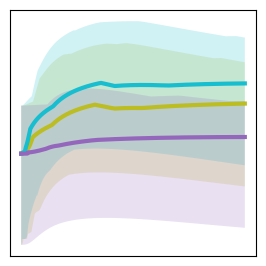

In [ ]:
ex_pypesto_problem = aic_pypesto_problems_dict["M100"]
ex_amici_model = ex_pypesto_problem.objective.amici_model
state_names = ex_amici_model.getStateNames()

state_index = 0

fig, axes = plot_states_overall(
    clust_0_ens,                    
    conditions=["MC1000", "ICZ", "BpA"],          
    percentiles=(25,75),
    state_names=state_names,
    nrows=6,
    ncols=3,
    suptitle=None,
    sharey=False,
    annotate_median=False,
    figsize=(3,3),
    state_index = state_index
)
# fig.savefig(f"results/model_selection/all_ligands_sacess_brute_force_mixed_noise/figures/clustering/new_aic_models_cluster_0_state_{state_index}_25_75.svg", bbox_inches="tight")

## Waterfall plots for some best models

In [40]:
import matplotlib as mpl
from matplotlib.ticker import FuncFormatter
model = "M99"

result = pypesto.store.read_result(f"results/model_selection/all_ligands_sacess_brute_force_mixed_noise/best/full_result_{model}.hdf5")

start_indices = np.arange(0, 100000)

Loading the profiling result failed. It is highly likely that no profiling result exists within output/model_selection/all_ligands_sacess_brute_force_mixed_noise/best/full_result_M99.hdf5.
Loading the sampling result failed. It is highly likely that no sampling result exists within output/model_selection/all_ligands_sacess_brute_force_mixed_noise/best/full_result_M99.hdf5.


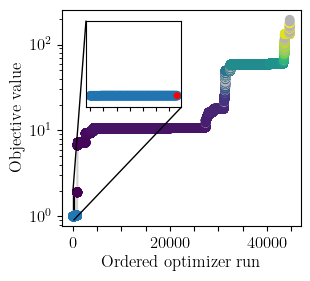

In [52]:
fig, axs = plt.subplots(1, 1, figsize=(fig_width/2, 0.7*fig_height), sharex=False)

# --- call pypesto + capture any new axes it created (the inset) -----

axes_before = set(fig.axes)
pypesto.visualize.waterfall(
    ax=axs,
    results=result,
    start_indices=start_indices,
    n_starts_to_zoom=100
)

blue = (0.12156863, 0.46666667, 0.70588235)
coll = axs.collections[0]

facecolors = coll.get_facecolors()
r = facecolors[:, 0]
g = facecolors[:, 1]
b = facecolors[:, 2]
red_mask = (r > 0.9) & (g < 0.2) & (b < 0.2)

# Set only the red points to blue (keep alpha as-is)
facecolors[red_mask, :3] = blue

coll.set_facecolors(facecolors)
new_axes = [a for a in fig.axes if a not in axes_before and a is not axs]

# --- tweak inset(s): remove title, move up a bit, de‑clutter ---------
for ins in new_axes:
    from mpl_toolkits.axes_grid1.inset_locator import InsetPosition
    import scipy.stats

    # keep layout engines from messing with the inset
    ins.set_in_layout(False)

    # place/resize inset as 40% x 40% of the parent axes (ax = axs[i])
    # [x0, y0, width, height] are in parent-axes fraction coords (0..1)
    ip = InsetPosition(axs, [0.1, 0.55, 0.40, 0.40]) 
    ins.set_axes_locator(ip)

    for coll in ins.collections:

        facecolors = coll.get_facecolors()
        r = facecolors[:, 0]
        g = facecolors[:, 1]
        b = facecolors[:, 2]
        red_mask = (r > 0.9) & (g < 0.2) & (b < 0.2)

        # Set only the red points to blue (keep alpha as-is)
        facecolors[red_mask, 0] = 0.12156863  # R
        facecolors[red_mask, 1] = 0.46666667  # G
        facecolors[red_mask, 2] = 0.70588235  # B
        edge = coll.get_edgecolors()
        if len(edge) > 0:
            r = edge[:, 0]; g = edge[:, 1]; b = edge[:, 2]
            red_mask = (r > 0.9) & (g < 0.2) & (b < 0.2)
            edge[red_mask, :3] = [0.12156863, 0.46666667, 0.70588235]
            coll.set_edgecolors(edge)
    for line in ins.lines:
        c = np.array(mpl.colors.to_rgb(line.get_color()))
        if np.allclose(c, [1, 0, 0], atol=0.05):   # was red
            line.set_color(blue)
            line.set_markerfacecolor(blue)
            line.set_markeredgecolor(blue)

    # remove "Waterfall plot"
    # ins.set_title("Top 100 starts", fontsize=18, fontweight='bold', fontstyle='italic')
    # lighten frame and ticks (optional)
    ins.tick_params(axis='both', labelsize=12, length=3)
    ins.set_xlabel("")  # inset doesn’t need its own xlabel
    ins.set_xticklabels("")
    # Remove the y-label
    ins.set_ylim(0.9, 2)

    ins.set_ylabel("")
    ins.tick_params(axis='y', which='both', left=False, labelleft=False)
    # shift inset upward in parent-axes coordinates
    bb = ins.get_position()
    ins.set_position([bb.x0, bb.y0 + 0.06, bb.width, bb.height])
    # Set the ylim of the inset to be (in log scale) from 1 to 1 + scipy.stats.chi2.ppf(0.95, df=1)

# --- your styling ----------------------------------------------------
axs.set_title('')
# axs.text(-0.1, 1.10, chr(65), transform=axs.transAxes,
#             fontsize=20, fontweight='bold', va='top', ha='left')

yl = "Objective value"
parts = yl.split(' ')
if len(parts) >= 3:
    yl = parts[0] + ' ' + parts[1] + '\n' + parts[2]
axs.set_ylabel(yl, fontsize=12)

# put xlabels only on bottom row
axs.set_xlabel('Ordered optimizer run', fontsize=12)

# Set y and x tick size of all plots
# axs.set_title(f"Waterfall Plot: {model}", fontsize=18)
# change fontsizes of all to 14
for item in ([axs.xaxis.label, axs.yaxis.label] +
             axs.get_xticklabels() + axs.get_yticklabels()):
    item.set_fontsize(12)
step = 4000  # label every 200th position
axs.xaxis.set_major_formatter(FuncFormatter(
    lambda val, pos: f"{int(val)}" if (int(round(val)) % step) == 0 else ""
))


plt.tight_layout()
plt.subplots_adjust(wspace=0.4, hspace=0.6)
plt.tight_layout()
plt.show()

fig.savefig(f"results/model_selection/all_ligands_sacess_brute_force_mixed_noise/figures/{model}_waterfall_plot.pdf", bbox_inches="tight")